## Data Loading, Storage, and File Formats

In [1]:
import pandas as pd


------------------------------------------
✅ Runtime: 310.1 ms | 💾 Mem: 109.67 MB (Δ +109.67 MB) | ⚙️ CPU: 17.4%


In [2]:
df = pd.read_csv("beton24_csv.csv/olchov.csv", names=["OlchovID", "OlchovNomi", "FilialID"])
df.head()

,OlchovID,OlchovNomi,FilialID
0,1,метр,1
1,2,кг,1
2,3,квадрат,1
3,4,куб,1
4,5,дона,1



------------------------------------------
✅ Runtime: 13.6 ms | 💾 Mem: 110.53 MB (Δ +0.86 MB) | ⚙️ CPU: 9.3%


In [3]:
parsed = pd.read_csv("examples/csv_mindex.csv", index_col=["key1", "key2"])
parsed # key1, key2 are together primary keys

value1  value2
key1 key2                
one  a          1       2
     b          3       4
     c          5       6
     d          7       8
two  a          9      10
     b         11      12
     c         13      14
     d         15      16


------------------------------------------
✅ Runtime: 8.9 ms | 💾 Mem: 110.92 MB (Δ +0.39 MB) | ⚙️ CPU: 0.0%


### Using \\s+ space delimetr
- separator \\s+ which means space can be more than 1
- if column names are fewer than actual number of columns below, pandas takes first column as a index


In [4]:
result = pd.read_csv("examples/ex3.txt", sep="\\s+")
result 

,A,B,C
aaa,-0.264438,-1.026059,-0.619500
bbb,0.927272,0.302904,-0.032399
ccc,-0.264273,-0.386314,-0.217601
ddd,-0.871858,-0.348382,1.100491



------------------------------------------
✅ Runtime: 6.1 ms | 💾 Mem: 111.06 MB (Δ +0.14 MB) | ⚙️ CPU: 0.0%


### Skipping useless lines
- can be titles, comments or anything

In [5]:
pd.read_csv("examples/ex4.txt", skiprows=[0,2,3]) 

EmptyDataError: No columns to parse from file


------------------------------------------
✅ Runtime: 224.4 ms | 💾 Mem: 127.52 MB (Δ +16.45 MB) | ⚙️ CPU: 0.0%


### Handling missing but sentinel (placeholder) values as NaN

In [ ]:
result = pd.read_csv("examples/ex5.csv", na_values=['NB'])
result

In [ ]:
pd.isna(result)

## Reading Text Files in Pieces
 - when processing very large files
 - through smaller chunks of the file

In [ ]:
pd.options.display.max_rows = 10
davomat_table_col_names = ['DavomatID', 'Yonalish', 'HodimID', 'FilialID', 'Tekshiruvchi', 'SanaVaqt', 'IshDaqiqa']
result = pd.read_csv("beton24_csv.csv/davomat.csv", names=davomat_table_col_names)
result

In [ ]:
result = pd.read_csv("beton24_csv.csv/davomat.csv", nrows=5, names=davomat_table_col_names)
result

#### Chunker

In [ ]:
chunker = pd.read_csv("beton24_csv.csv/davomat.csv", chunksize=1000, header=None)
tot = pd.Series([], dtype='int64')
for piece in chunker:
     tot = tot.add(piece[1].value_counts(), fill_value=0)
tot = tot.sort_values(ascending=False)
tot

## this is like GROUP BY and COUNT in SQL

### Writing Data to Text Format

In [ ]:
data = pd.read_csv("beton24_csv.csv/olchov.csv", header=None)
data.drop(2, axis=1).to_csv("outputs/measurements.csv", index=False, header=False, sep='|')

In [ ]:
data = pd.read_csv("beton24_csv.csv/olchov.csv", names=["OlchovID", "OlchovNomi", "FilialID"])
data.to_json("outputs/olchov.json", orient="records")

## XML and HTML: Web Scraping

In [ ]:
tables = pd.read_html("examples/countries_mineral_production.html", na_values=['–'])
tables[1]

### Binary Data Formats
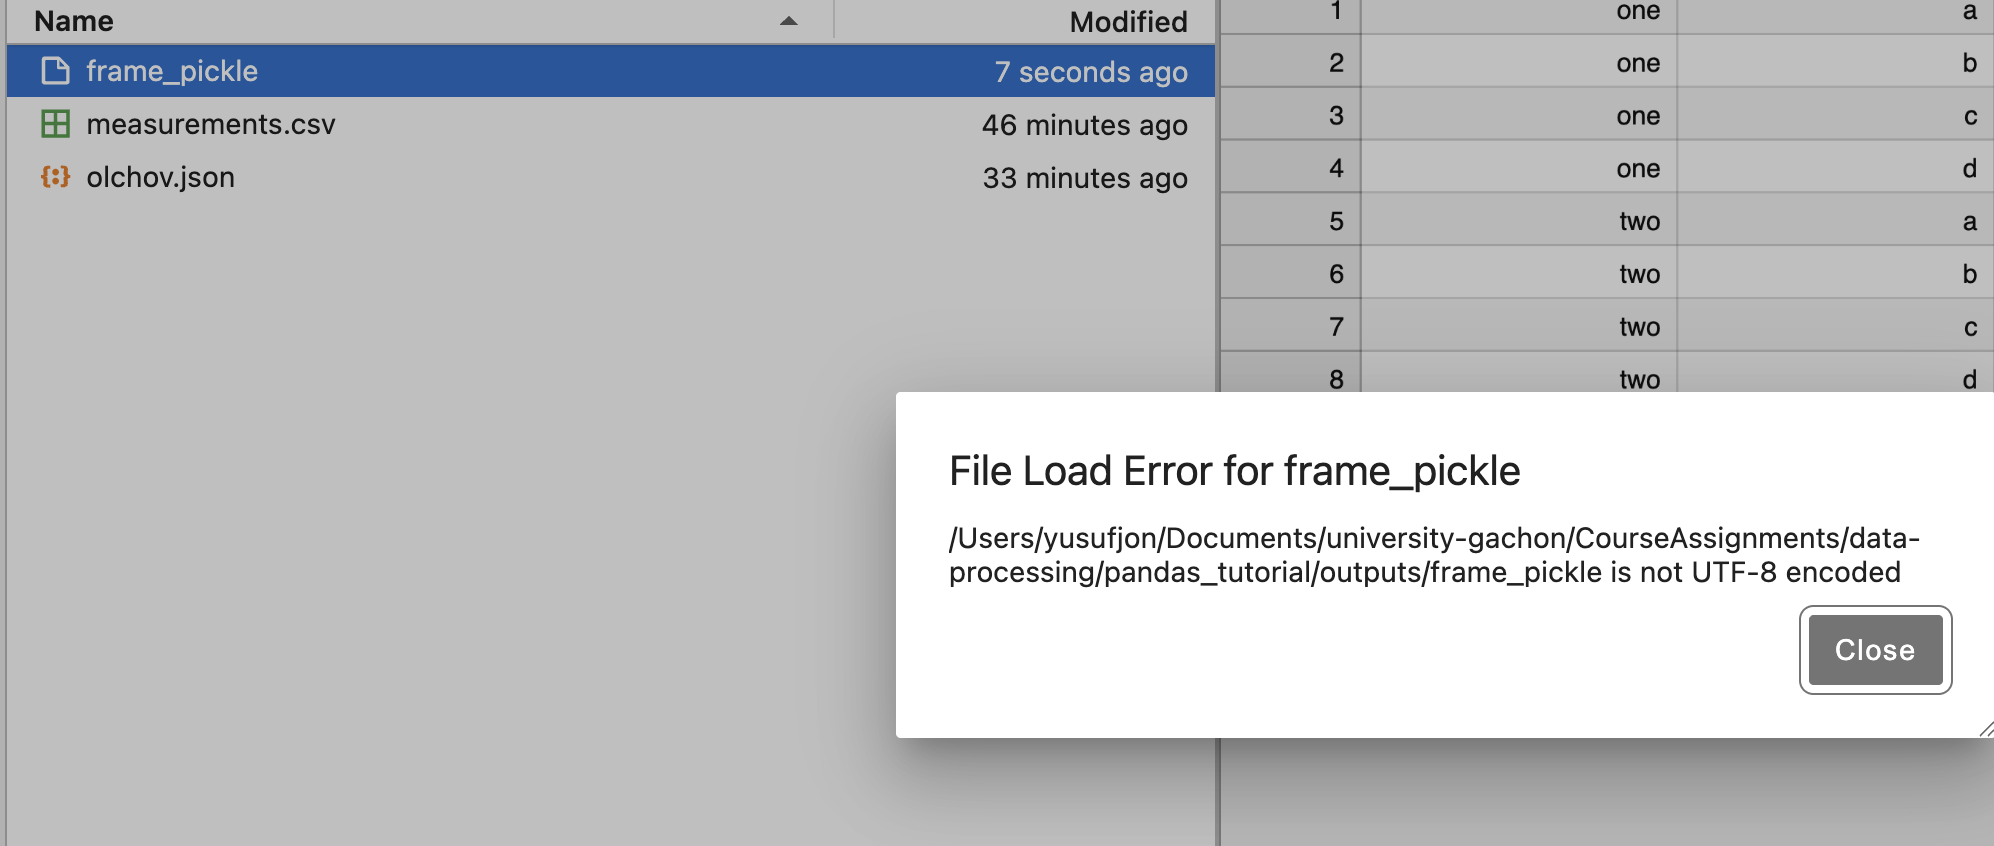

In [ ]:
frame = pd.read_csv("examples/csv_mindex.csv")
frame.to_pickle("outputs/frame_pickle")
pd.read_pickle("outputs/frame_pickle")

### Reading Microsoft Excel Files

In [ ]:
xlsx = pd.read_excel("examples/Historicalinvesttemp.xlsx", sheet_name="Sheet1", skiprows=6)
xlsx

### Using HDF5 Format  

In [ ]:
import numpy as np
columns = np.array((('a', None, None, None, None, None, None),
('b', None, None, None, None, None, None),
('c', None, None, None, None, None, None),
('d', None, None, None, None, None, None)))
columns[:, :1].reshape(1,4)

 ### Interacting with Web APIs

In [ ]:
import requests
url = "https://api.github.com/repos/pandas-dev/pandas/issues"
resp = requests.get(url)
resp.raise_for_status()
resp

In [ ]:
data = resp.json()
data[0]["title"]

In [ ]:
issues = pd.DataFrame(data, columns=["number", "title", "labels", "state"])
issues

### Interacting with Databases

## Data Cleaning and Preparation

### Handling Missing Data

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
float_data = pd.Series([1.2, -3.5, np.nan, 0])
float_data

In [ ]:
float_data.isna()

In [ ]:
float_data.notna()

In [ ]:
string_data = pd.Series(["aardvark", np.nan, None, "avocado"])
string_data.isna()

In [ ]:
string_data.dropna()

In [ ]:
string_data.fillna("Filled")

#### Filtering Out Missing Data

In [ ]:
data = pd.DataFrame([[1., 6.5, 3.], [1., np.nan, np.nan], [np.nan, np.nan, np.nan], [np.nan, 6.5, 3.]])


In [ ]:
# dropna by default drops any row containing a missing value:
data.dropna()

In [ ]:
# Passing how="all" will drop only rows that are all NA:
data.dropna(how='all')

In [ ]:
data.dropna(thresh=1)

#### Filling data

In [ ]:
data.fillna(data.mean())

In [ ]:
data.ffill(limit=2)

### Data Transformation
#### Removing Duplicates

In [ ]:
data = pd.DataFrame({
    "k1": ["one", "two"] * 3 + ["two"], 
    "k2": [1, 1, 2, 3, 3, 4, 4]
})
data.duplicated()

In [ ]:
data.drop_duplicates()

In [ ]:
data.drop_duplicates(subset=["k1"]) # by specific columns
data.drop_duplicates(["k1", "k2"], keep="last")

### Transforming Data Using a Function or Mapping

In [ ]:
data = pd.DataFrame({
    "food": ["bacon", "pulled pork", "bacon", "pastrami", "corned beef", "bacon","pastrami", "honey ham", "nova lox"],
     "ounces": [4, 3, 12, 6, 7.5, 8, 3, 5, 6]})

meat_to_animal = {
 "bacon": "pig",
 "pulled pork": "pig",
 "pastrami": "cow",
 "corned beef": "cow",
 "honey ham": "pig",
 "nova lox": "salmon"
}

def animal_name(x):
    return meat_to_animal[x]

data['food'].map(animal_name)

### Replacing Values

In [ ]:
pd.Series([1., -999., 2., -999., -1000., 3.]).replace(-999., np.nan)

In [ ]:
pd.Series([1., -999., 2., -999., -1000., 3.]).replace([-999., -1000.], np.nan)

In [ ]:
data = pd.DataFrame(np.arange(12).reshape((3, 4)),
 index=["Ohio", "Colorado", "New York"],
 columns=["one", "two", "three", "four"])

data

In [ ]:
def transform(x):
    return x[:4].upper()
data.index = data.index.map(transform)

In [ ]:
data

In [ ]:
data.rename(index=str.title, columns=str.upper)

### Discretization and Binning

In [ ]:
## Grouping ages by age catregories

ages = [20, 22, 25, 27, 21, 23, 37, 31, 61, 45, 41, 32]
bins = [18, 25, 35, 60, 100]

age_categories = pd.cut(ages, bins)
print(age_categories)
age_categories.value_counts()

### Detecting and Filtering Outliers

In [ ]:
data = pd.DataFrame(np.random.standard_normal((1000, 4)))
col = data[2]
col[col.abs() > 3]

In [ ]:
data[(data.abs() > 3).any(axis="columns")]

In [ ]:
np.sign(data).head()

### Permutation and Random Sampling

In [ ]:
df = pd.DataFrame(np.arange(5 * 7).reshape((5, 7)))
df

In [ ]:
sampler = np.random.permutation(5)
sampler

In [ ]:
df.take(sampler) 
df.iloc[sampler]

In [ ]:
## getting random subset uniquely
df.sample(n=3)

In [ ]:
## getting random subsets with possible repetitions
df.sample(n=10, replace=True)

### Computing Indicator/Dummy Variables
A dummy variable (also called an indicator variable) is a binary variable (0 or 1) created to represent categories in your dataset numerically — because most models (like regression, SVM, etc.) only work with numbers.

In [ ]:
df = pd.DataFrame({"key": ["b", "b", "a", "c", "a", "b"],"data1": range(6)})
df

In [ ]:
pd.get_dummies(df["key"])

In [ ]:
dummies = pd.get_dummies(df["key"], prefix="key")
df_with_dummy = df[["data1"]].join(dummies)
df_with_dummy

In [ ]:
np.random.seed(12345)
values = np.random.uniform(size=10)
values

###  Extension Data Types

In [ ]:
df = pd.DataFrame({"A": [1, 2, None, 4],
 "B": ["one", "two", "three", None],
 "C": [False, None, False, True]})

In [ ]:
df["A"] = df["A"].astype("Int64")
df["B"] = df["B"].astype("string")
df["C"] = df["C"].astype("boolean")
df

### Regular Expressions

In [ ]:
import re

#### Methods to search for matches

In [ ]:
test_string = "123abc4567abc123ABC"

pattern = re.compile(r"abc")
matches = pattern.finditer(test_string)

for m in matches:
    print(m)

In [ ]:
pattern.findall(test_string)

In [ ]:
pattern.match(test_string) 
### should be at the beginning of string

In [ ]:
pattern.search(test_string)
### returns only one match

#### Methods on a match object

In [ ]:
test_string = "123abc4567abc123ABC"

pattern = re.compile(r"abc")
matches = pattern.finditer(test_string)

for m in matches:
    print(m.span(), m.start(), m.end())
    print(m.group())

#### Meta characters

In [ ]:
test_string = "123abc.4567abc123ABC"

#pattern = re.compile(r"\.") # \ used before special characters
#pattern = re.compile(r"^123") # match start
pattern = re.compile(r"ABC$")  # match end
matches = pattern.finditer(test_string)

for m in matches:
    print(m)

#### More special sequences

In [ ]:
test_string = "hello 123_ heyho hihey"

pattern = re.compile(r"\bhey")  # match with start of block 
matches = pattern.finditer(test_string)

for m in matches:
    print(m)

#### Sets

In [ ]:
test_string = "helloCOKE 123_"

# pattern = re.compile(r"[lo]") # matches l and o, not lo
pattern = re.compile(r'[a-zA-Z0-2]') # range or [0-9] or [A-Z]
matches = pattern.finditer(test_string)

for m in matches:
    print(m)

#### Quantifiers

In [ ]:
test_string = "hello_123"

#pattern = re.compile(r'\d+') # concatines all matches 
#pattern = re.compile(r'_?\d') # ? means optional
# pattern = re.compile(r'\d{1,3}') # {} digit of match

matches = pattern.finditer(test_string)

for m in matches:
    print(m)

In [ ]:
dates = """
01.04.2020
2020.04.01
2020-04-01
2020-05-23
2020-06-11
2020-07-11
2020-08-11

2020/04/02

2020_04_04
2020__04_04
"""
pattern = re.compile(r'\d{4}[-\.]0[5-7][-\.]\d{2}')
matches = pattern.finditer(dates)

for m in matches:
    print(m)

#### Conditions

In [ ]:
my_string = """
hello world
12323
2020-07-23
Mr Simpson
Mrs Simpson
Mr. Brown
Ms Smith
Mr. T
"""

pattern = re.compile(r'\d{4}[-\.]0[5-7][-\.]\d{2}')
matches = pattern.finditer(my_string)

for m in matches:
    print(m)


#### Grouping

In [ ]:
my_string = """
hello world
12323
2020-07-23
Mr Simpson
Mrs Simpson
Mr. Brown
Ms Smith
Mr. T
dnoqwiever@gmia.com
ewvr-ij123@gmx.uz
32efwio4pgm@dwfe3.org
"""

### pattern = re.compile(r'[a-zA-Z0-9-]+@[a-zA-Z]+\.(com|uz|ru|org)')
pattern = re.compile(r'([a-zA-Z0-9-]+)@([a-zA-Z]+)\.(com|uz|ru|org)')
matches = pattern.finditer(my_string)

for m in matches:
    print(m.group(0)) # all matched string
    print(m.group(2)) # domain
    print(m.group(3)) # top level domain


#### Modification

In [ ]:
test_string = 'hello world, you  the best world'

pattern = re.compile(r'world')
# matches = pattern.split(test_string) # split by 'world'
subbedstring = pattern.sub('planet', test_string)

print(subbedstring)

### String Functions in pandas

In [ ]:
data = pd.Series({"Dave": "dave@google.com", "Steve": "steve@gmail.com",
 "Rob": "rob@gmail.com", "Wes": np.nan})
data

In [ ]:
data.str.contains('gmail')


### Categorical data

In [ ]:
values = pd.Series([0,1,0,0]*2)
dim = pd.Series(['apple', 'orange'])

### 0  refers to one category, 1 also does. 
### so they are called categorical data

dim.take(values)

- Renaming categories
- Appending a new category are considered low-cost transformations using categories

In [ ]:
import numpy as np
fruits = ['apple', 'orange', 'apple', 'apple'] * 2
N = len(fruits)
rng = np.random.default_rng(seed=12345)

df = pd.DataFrame({
      'fruit': fruits,
      'basket_id': np.arange(N),
      'count': rng.integers(3, 15, size=N),
      'weight': rng.uniform(0, 4, size=N)
}, columns=['basket_id', 'fruit', 'count', 'weight'])
fruit_cat = df['fruit'].astype('category')
fruit_cat

In [ ]:
c = fruit_cat.array
# type(c)
# c.categories
# c.codes
dict(enumerate(c.categories))

In [ ]:
my_categories = pd.Categorical(['foo', 'bar', 'baz', 'foo', 'bar'])
my_categories

In [6]:
pd.Categorical.from_codes([0,2,1,1,2,3,2,1,2,3], ['olma', 'behi', 'anjir', 'jiyda'], ordered=True)


['olma', 'anjir', 'behi', 'behi', 'anjir', 'jiyda', 'anjir', 'behi', 'anjir', 'jiyda']
Categories (4, object): ['olma' < 'behi' < 'anjir' < 'jiyda']


------------------------------------------
✅ Runtime: 10.0 ms | 💾 Mem: 127.59 MB (Δ +0.08 MB) | ⚙️ CPU: 21.4%


### Categorical Methods

In [27]:
s = pd.Series(['a','b','c','d']*2)
cat_s = s.astype('category')
cat_s.cat.codes

0    0
1    1
2    2
3    3
4    0
5    1
6    2
7    3
dtype: int8


------------------------------------------
✅ Runtime: 10.4 ms | 💾 Mem: 113.77 MB (Δ +0.02 MB) | ⚙️ CPU: 61.5%


In [39]:
# Categorical methods for  Series in pandas
# cat_sn = cat_s.cat.add_categories(['e', 'f'])
# cat_sn.cat.as_ordered()
# cat_sn.cat.as_unordered()
# cat_sn = cat_s.cat.remove_categories(['b', 'd'])
# cat_sn = cat_s.cat.remove_unused_categories()
# cat_sn = cat_s.cat.rename_categories({'a':'f', 'b':'l'})
cat_sn = cat_s.cat.set_categories({'a':'f', 'b':'l'})
cat_sn

0      a
1      b
2    NaN
3    NaN
4      a
5      b
6    NaN
7    NaN
dtype: category
Categories (2, object): ['a', 'b']


------------------------------------------
✅ Runtime: 10.2 ms | 💾 Mem: 122.45 MB (Δ +0.03 MB) | ⚙️ CPU: 15.9%


# Chapter 8 | Data Wrangling: Join, Combine, and Reshape

## 8.1 Hierarchical Indexing | (Rowspan, Colspan in HTML table)

In [45]:
import numpy as np

data = pd.Series(np.random.uniform(size=9),
 index=[["a", "a", "a", "b", "b", "c", "c", "d", "d"],
 [1, 2, 3, 1, 3, 1, 2, 2, 3]])
print(data.index)
data

MultiIndex([('a', 1),
            ('a', 2),
            ('a', 3),
            ('b', 1),
            ('b', 3),
            ('c', 1),
            ('c', 2),
            ('d', 2),
            ('d', 3)],
           )


a  1    0.174458
   2    0.774687
   3    0.779598
b  1    0.982263
   3    0.080871
c  1    0.378826
   2    0.639461
d  2    0.398884
   3    0.094730
dtype: float64


------------------------------------------
✅ Runtime: 14.5 ms | 💾 Mem: 162.41 MB (Δ +0.03 MB) | ⚙️ CPU: 18.9%


In [46]:
data.loc[:, 2] ## first one first level index, 2nd one second level index

a    0.774687
c    0.639461
d    0.398884
dtype: float64


------------------------------------------
✅ Runtime: 6.9 ms | 💾 Mem: 162.42 MB (Δ +0.02 MB) | ⚙️ CPU: 25.0%


In [54]:
## x axis can also have a hierarchical index:
frame = pd.DataFrame(np.arange(12).reshape((4, 3)),
  index=[["a", "a", "b", "b"], [1, 2, 1, 2]],
  columns=[["Ohio", "Ohio", "Colorado"],
  ["Green", "Red", "Green"]])
frame.columns.names = ["state", "color"]
frame.index.names = ["key1", "key2"]
frame

state      Ohio     Colorado
color     Green Red    Green
key1 key2                   
a    1        0   1        2
     2        3   4        5
b    1        6   7        8
     2        9  10       11


------------------------------------------
✅ Runtime: 20.0 ms | 💾 Mem: 52.06 MB (Δ -110.42 MB) | ⚙️ CPU: 51.2%


In [53]:
## Reordering and Sorting Levels


------------------------------------------
✅ Runtime: 0.9 ms | 💾 Mem: 162.48 MB (Δ +0.02 MB) | ⚙️ CPU: 37.8%


In [55]:
frame.swaplevel(0,1)

state      Ohio     Colorado
color     Green Red    Green
key2 key1                   
1    a        0   1        2
2    a        3   4        5
1    b        6   7        8
2    b        9  10       11


------------------------------------------
✅ Runtime: 13.7 ms | 💾 Mem: 52.64 MB (Δ +0.58 MB) | ⚙️ CPU: 16.3%


In [57]:
frame.groupby(level="key1").sum()

state  Ohio     Colorado
color Green Red    Green
key1                    
a         3   5        7
b        15  17       19


------------------------------------------
✅ Runtime: 10.2 ms | 💾 Mem: 53.95 MB (Δ -0.95 MB) | ⚙️ CPU: 33.3%


In [59]:
frame.T.groupby(level="color").sum()

key1   a      b    
key2   1  2   1   2
color              
Green  2  8  14  20
Red    1  4   7  10


------------------------------------------
✅ Runtime: 16.6 ms | 💾 Mem: 55.16 MB (Δ +0.48 MB) | ⚙️ CPU: 19.5%


### Indexing with a DataFrame’s columns

In [63]:
frame = pd.DataFrame({"a": range(7), "b": range(7, 0, -1),
 "c": ["one", "one", "one", "two", "two",
 "two", "two"],
 "d": [0, 1, 2, 0, 1, 2, 3]})
frame2 = frame.set_index(['c','d'], drop=False)
frame2

a  b    c  d
c   d              
one 0  0  7  one  0
    1  1  6  one  1
    2  2  5  one  2
two 0  3  4  two  0
    1  4  3  two  1
    2  5  2  two  2
    3  6  1  two  3


------------------------------------------
✅ Runtime: 33.6 ms | 💾 Mem: 56.17 MB (Δ +0.12 MB) | ⚙️ CPU: 50.0%


## 8.2 Combining and Merging Datasets

### Database-Style DataFrame Joins

In [64]:
df1 = pd.DataFrame({"key": ["b", "b", "a", "c", "a", "a", "b"],
"data1": pd.Series(range(7), dtype="Int64")})
df2 = pd.DataFrame({"key": ["a", "b", "d"],
"data2": pd.Series(range(3), dtype="Int64")})


------------------------------------------
✅ Runtime: 5.3 ms | 💾 Mem: 57.02 MB (Δ +0.84 MB) | ⚙️ CPU: 17.9%


In [65]:
pd.merge(df1, df2)

,key,data1,data2
0,b,0,1
1,b,1,1
2,a,2,0
3,a,4,0
4,a,5,0
5,b,6,1



------------------------------------------
✅ Runtime: 18.9 ms | 💾 Mem: 58.95 MB (Δ +1.94 MB) | ⚙️ CPU: 26.2%


In [165]:
production = pd.read_csv("beton24_csv.csv/production.csv", names=["id", "product_id", "seh_id", "value", "qoldiq", "filial_id", "user_id", "date", "tannarx", "omborchi", "journey_id", "plan_id", "silos_id", "smena_id"], usecols=["product_id", "value", "date", "tannarx"])
product = pd.read_csv("beton24_csv.csv/product.csv", names=["id", "name", "savdo_kpi", "loading_kpi", "narx", "vitrina_narx", "tp_id", "image", "date", "filial_id", "bil_value", "status", "has_warehouse", "butun", "pressure", "type", "orderNumber", "bonus_need", "bonus_value"], usecols=['id', 'name'])

table1 = pd.merge(production, product, left_on="product_id", right_on="id")
table1["date"] = table1["date"].map(lambda x: x[:10])

# table1 = table1[table1.date[:4]=='2024']

table1 = table1.drop(columns=['id'])
table1['name'] = table1['name'].astype('category')
table1['product_id'] = table1['product_id'].astype('category')
table1['date'] = pd.to_datetime(table1['date'], errors='coerce')


table1 = table1[['product_id', 'name', 'value', 'tannarx', 'date']]


summary = (
    table1.groupby(["product_id", "name"], observed=False, as_index=False)['value']
    .sum()
    .rename(columns={'value': 'total'})
    .sort_values('total', ascending=False)
)

summary.head(10)


,product_id,name,total
1040,9,БЕТОН М250 B20,31711.810
694,8,БЕТОН М200 В15,14824.590
84139,463,50/25/5 СЕРЫЙ,13690.472
1891,11,БЕТОН М350 В25,13034.850
527,7,БЕТОН М150 В10,9743.740
96507,504,ПОГРУЗКА БРУСЧАТКИ,8430.000
12530,93,ПОРЕБРИК 1 М БОРДЮР,8288.000
64293,392,БЕТОН М350 B25 СУЛЬФОТОСТОЙКИЙ,6078.100
97526,507,ПОГРУЗКА БОРДЮРА,5904.000
1390,10,"БЕТОН М300 В22,5",4645.550



------------------------------------------
✅ Runtime: 56.1 ms | 💾 Mem: 152.59 MB (Δ +21.11 MB) | ⚙️ CPU: 36.4%


### Concatenating Along an Axis

In [123]:
arr = np.arange(12).reshape((3, 4))


------------------------------------------
✅ Runtime: 1.5 ms | 💾 Mem: 242.03 MB (Δ -84.58 MB) | ⚙️ CPU: 25.0%


In [124]:
np.concatenate([arr, arr], axis=1)

array([[ 0,  1,  2,  3,  0,  1,  2,  3],
       [ 4,  5,  6,  7,  4,  5,  6,  7],
       [ 8,  9, 10, 11,  8,  9, 10, 11]])


------------------------------------------
✅ Runtime: 7.6 ms | 💾 Mem: 242.14 MB (Δ +0.11 MB) | ⚙️ CPU: 25.6%


In [127]:
s1 = pd.Series([0, 1], index=["a", "b"], dtype="Int64")
s2 = pd.Series([2, 3, 4], index=["c", "d", "e"], dtype="Int64")
s3 = pd.Series([5, 6], index=["f", "g"], dtype="Int64")

pd.concat([s1, s2, s3])

a    0
b    1
c    2
d    3
e    4
f    5
g    6
dtype: Int64


------------------------------------------
✅ Runtime: 6.5 ms | 💾 Mem: 242.28 MB (Δ +0.00 MB) | ⚙️ CPU: 18.2%


In [128]:
pd.concat([s1, s2, s3], axis="columns")

,0,1,2
a,0,<NA>,<NA>
b,1,<NA>,<NA>
c,<NA>,2,<NA>
d,<NA>,3,<NA>
e,<NA>,4,<NA>
f,<NA>,<NA>,5
g,<NA>,<NA>,6



------------------------------------------
✅ Runtime: 14.2 ms | 💾 Mem: 242.31 MB (Δ +0.03 MB) | ⚙️ CPU: 27.7%


In [130]:
s4 = pd.concat([s1, s3])
pd.concat([s1, s4], axis="columns", join="inner") ## intersect

,0,1
a,0,0
b,1,1



------------------------------------------
✅ Runtime: 16.6 ms | 💾 Mem: 242.50 MB (Δ +0.14 MB) | ⚙️ CPU: 22.2%


In [133]:
result = pd.concat([s1, s1, s3], keys=["one", "two", "three"])
result.unstack()

,a,b,f,g
one,0,1,<NA>,<NA>
two,0,1,<NA>,<NA>
three,<NA>,<NA>,5,6



------------------------------------------
✅ Runtime: 25.9 ms | 💾 Mem: 244.91 MB (Δ +2.38 MB) | ⚙️ CPU: 21.4%


In [136]:
df1 = pd.DataFrame(np.arange(6).reshape(3, 2), index=["a", "b", "c"],
 columns=["one", "two"])
df2 = pd.DataFrame(5 + np.arange(4).reshape(2, 2), index=["a", "c"],
 columns=["three", "four"])

pd.concat([df1, df2], axis="columns", keys=["level1", "level2"])


level1     level2     
     one two  three four
a      0   1    5.0  6.0
b      2   3    NaN  NaN
c      4   5    7.0  8.0


------------------------------------------
✅ Runtime: 19.1 ms | 💾 Mem: 171.45 MB (Δ +0.05 MB) | ⚙️ CPU: 31.1%


In [138]:
pd.concat([df1, df2], axis="columns", keys=["level1", "level2"],
names=["upper", "lower"])

upper level1     level2     
lower    one two  three four
a          0   1    5.0  6.0
b          2   3    NaN  NaN
c          4   5    7.0  8.0


------------------------------------------
✅ Runtime: 15.5 ms | 💾 Mem: 171.58 MB (Δ +0.00 MB) | ⚙️ CPU: 34.9%


### Combining Data with Overlap

In [139]:
a = pd.Series([np.nan, 2.5, 0.0, 3.5, 4.5, np.nan],
 index=["f", "e", "d", "c", "b", "a"])
b = pd.Series([0., np.nan, 2., np.nan, np.nan, 5.],
 index=["a", "b", "c", "d", "e", "f"])


------------------------------------------
✅ Runtime: 1.3 ms | 💾 Mem: 171.59 MB (Δ +0.02 MB) | ⚙️ CPU: 23.3%


In [140]:
a.combine_first(b) ## automatically chooses non-nans 

a    0.0
b    4.5
c    3.5
d    0.0
e    2.5
f    5.0
dtype: float64


------------------------------------------
✅ Runtime: 12.5 ms | 💾 Mem: 171.83 MB (Δ +0.23 MB) | ⚙️ CPU: 27.9%


## 8.3 Reshaping and Pivoting

### Reshaping with Hierarchical Indexing

- stack - This “rotates” or pivots from the columns in the data to the rows.
- unstack - This pivots from the rows into the columns

In [141]:
data = pd.DataFrame(np.arange(6).reshape((2, 3)),
  index=pd.Index(["Ohio", "Colorado"], name="state"),
  columns=pd.Index(["one", "two", "three"],
  name="number"))
data

number,one,two,three
state,,,
Ohio,0,1,2
Colorado,3,4,5



------------------------------------------
✅ Runtime: 11.2 ms | 💾 Mem: 171.83 MB (Δ +0.00 MB) | ⚙️ CPU: 25.0%


In [142]:
data.stack()

state     number
Ohio      one       0
          two       1
          three     2
Colorado  one       3
          two       4
          three     5
dtype: int64


------------------------------------------
✅ Runtime: 10.7 ms | 💾 Mem: 141.91 MB (Δ -29.92 MB) | ⚙️ CPU: 20.0%


In [143]:
data.unstack()

number  state   
one     Ohio        0
        Colorado    3
two     Ohio        1
        Colorado    4
three   Ohio        2
        Colorado    5
dtype: int64


------------------------------------------
✅ Runtime: 13.5 ms | 💾 Mem: 142.02 MB (Δ +0.11 MB) | ⚙️ CPU: 19.0%


In [146]:
data.stack().unstack(level=0)

state,Ohio,Colorado
number,,
one,0,3
two,1,4
three,2,5



------------------------------------------
✅ Runtime: 10.9 ms | 💾 Mem: 142.05 MB (Δ +0.02 MB) | ⚙️ CPU: 38.6%


### Pivoting "Long" to "Wide" Format
In some cases, the data may be more difficult to work with
in this format; you might prefer to have a DataFrame containing one column per
distinct item value indexed by timestamps in the date column. DataFrame’s pivot
method performs exactly this transformation:

In [161]:
long_data = pd.DataFrame({
    'date': [
        '1959-01-01','1959-01-01','1959-01-01',
        '1959-04-01','1959-04-01','1959-04-01',
        '1959-07-01','1959-07-01','1959-07-01',
        '1959-10-01'
    ],
    'item': [
        'realgdp','infl','unemp',
        'realgdp','infl','unemp',
        'realgdp','infl','unemp',
        'realgdp'
    ],
    'value': [
        2710.349,0.0,5.8,
        2778.801,2.34,5.1,
        2775.488,2.74,5.3,
        2785.204
    ]
})

pivoted1 = long_data.pivot(index="date", columns="item", values="value")
pivoted1.head()

item,infl,realgdp,unemp
date,,,
1959-01-01,0.00,2710.349,5.8
1959-04-01,2.34,2778.801,5.1
1959-07-01,2.74,2775.488,5.3
1959-10-01,NaN,2785.204,NaN



------------------------------------------
✅ Runtime: 19.0 ms | 💾 Mem: 130.86 MB (Δ +0.03 MB) | ⚙️ CPU: 25.0%


In [162]:
long_data["value2"] = np.random.standard_normal(len(long_data))
pivoted = long_data.pivot(index="date", columns="item")
pivoted.head()

value                    value2                    
item        infl   realgdp unemp      infl   realgdp     unemp
date                                                          
1959-01-01  0.00  2710.349   5.8 -2.341707  0.102541 -1.005772
1959-04-01  2.34  2778.801   5.1 -0.139210 -1.102086  0.236027
1959-07-01  2.74  2775.488   5.3 -0.555862 -0.797283 -0.905541
1959-10-01   NaN  2785.204   NaN       NaN  1.313561       NaN


------------------------------------------
✅ Runtime: 20.6 ms | 💾 Mem: 130.88 MB (Δ +0.02 MB) | ⚙️ CPU: 56.5%


### "Wide" to "Long" Pivoting

In [163]:

pivoted1 = pivoted1.reset_index()

pd.melt(pivoted1, id_vars="date", value_vars=["infl", "realgdp", "unemp"])

,date,item,value
0,1959-01-01,infl,0.000
1,1959-04-01,infl,2.340
2,1959-07-01,infl,2.740
3,1959-10-01,infl,NaN
4,1959-01-01,realgdp,2710.349
5,1959-04-01,realgdp,2778.801
6,1959-07-01,realgdp,2775.488
7,1959-10-01,realgdp,2785.204
8,1959-01-01,unemp,5.800
9,1959-04-01,unemp,5.100



------------------------------------------
✅ Runtime: 17.4 ms | 💾 Mem: 130.98 MB (Δ +0.11 MB) | ⚙️ CPU: 19.0%


In [176]:
## production long to wide reshaping, from hamkorqurilish daily report
table3 = (
    table1.groupby(["date", "name"], observed=False, as_index=False)['value']
    .sum()
    .sort_values('date', ascending=False)
)

table3.head(10)
tabl4 = table3.pivot(index="date", columns="name", values="value")
tabl4[(tabl4 > 0).any(axis=1)].iloc[:10, :5]

name,Колонны железобетонные 4 КФ-109-4,2ПК 21.10 8A (III) в С9,БЕТОН - М250 B20,"БЕТОН - М300 B22,5",БЕТОН М100 B7.5 мелькозерность с 2% Антиморозом
date,,,,,
2014-12-03,0.0,0.0,0.0,0.0,0.0
2014-12-16,0.0,0.0,0.0,0.0,8.0
2014-12-17,0.0,0.0,0.0,0.0,8.0
2014-12-28,0.0,0.0,0.0,0.0,0.0
2022-12-22,0.0,0.0,0.0,0.0,0.0
2023-04-21,0.0,0.0,0.0,0.0,0.0
2023-06-01,0.0,0.0,0.0,0.0,0.0
2023-06-02,0.0,0.0,0.0,0.0,0.0
2023-06-03,0.0,0.0,0.0,0.0,0.0



------------------------------------------
✅ Runtime: 99.6 ms | 💾 Mem: 105.25 MB (Δ -240.50 MB) | ⚙️ CPU: 8.9%
